# APRAU 2026/27: Grupo 18 — Análise complementar

**Autor:** Lourenço Mendes (n.º 1201270)

Complementa o notebook principal (`aprau_grupo18.ipynb`) em dois pontos pedidos no enunciado:

1. **Análise bivariada das features categóricas** com os dois alvos (o notebook principal analisa só as numéricas).
2. **Efeito dos métodos de reamostragem na variância** das estimativas de desempenho.

Usa o mesmo dataset e o mesmo pré-processamento do notebook principal.

## 0. Setup

In [1]:
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import f1_score

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

# Mesma lógica do notebook principal: Google Drive no Colab, raiz do repo em execução local
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DATASET_PATH = '/content/drive/MyDrive/APRAU/dataset_grupo_18.csv'
else:
    CANDIDATES = ['../dataset_grupo_18.csv', '../../T/dataset_grupo_18.csv', 'dataset_grupo_18.csv']
    DATASET_PATH = next(p for p in CANDIDATES if os.path.exists(p))

df = pd.read_csv(DATASET_PATH)
print('Dataset:', DATASET_PATH, df.shape)

Dataset: ../dataset_grupo_18.csv (2000, 35)


In [2]:
# Same preprocessing as the main notebook (sections 2.6 and 2.8)
df_clean = df.drop(columns=['calcium_baseline', 'systolic_index', 'age_normalized'])
CAT_COLS = [c for c in df_clean.select_dtypes(exclude=[np.number]).columns if c != 'target_class']

df_enc = pd.get_dummies(df_clean, columns=CAT_COLS, drop_first=True, dtype=int)
df_enc['target_class'] = LabelEncoder().fit_transform(df_clean['target_class'])   # DI=0, HT=1, N=2
FEATURES = [c for c in df_enc.columns if c not in ['target_regression', 'target_class']]
X_all = df_enc[FEATURES].values
y_class = df_enc['target_class'].values
print(f'{len(FEATURES)} features | {len(CAT_COLS)} categóricas')

40 features | 12 categóricas


---
## 1. Análise bivariada das features categóricas

### 1.1 Categóricas vs `target_class`

A correlação de Pearson só se aplica a variáveis numéricas. Para duas variáveis categóricas usamos:
- **Teste do qui-quadrado:** compara a tabela de contingência observada com a que se esperaria se as variáveis fossem independentes. Um p-value pequeno (< 0.05) indica associação.
- **V de Cramér:** mede a **força** da associação, entre 0 (nenhuma) e 1 (total). O p-value sozinho não chega, porque com 2000 pacientes até associações muito fracas são significativas.

In [3]:
rows = []
for c in CAT_COLS:
    table = pd.crosstab(df[c], df['target_class'])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({'Feature': c, 'chi2': round(chi2, 1), 'p-value': p, 'V de Cramér': round(v, 3)})
cat_vs_class = pd.DataFrame(rows).sort_values('V de Cramér', ascending=False).reset_index(drop=True)
cat_vs_class

,Feature,chi2,p-value,V de Cramér
0,age_level,144.3,1.250467e-28,0.190
1,smoking,98.2,2.412624e-20,0.157
2,bmi_level,53.1,1.097039e-09,0.115
3,gender,25.6,2.728572e-06,0.113
4,family_history,25.4,3.013804e-06,0.113
5,low_hdl_cholesterol,18.5,9.846934e-05,0.096
6,education_level,27.7,1.412791e-05,0.083
7,physical_activity,25.9,3.281925e-05,0.081
8,sugar_consumption,25.0,5.035888e-05,0.079
9,high_ldl_cholesterol,7.6,2.204889e-02,0.062


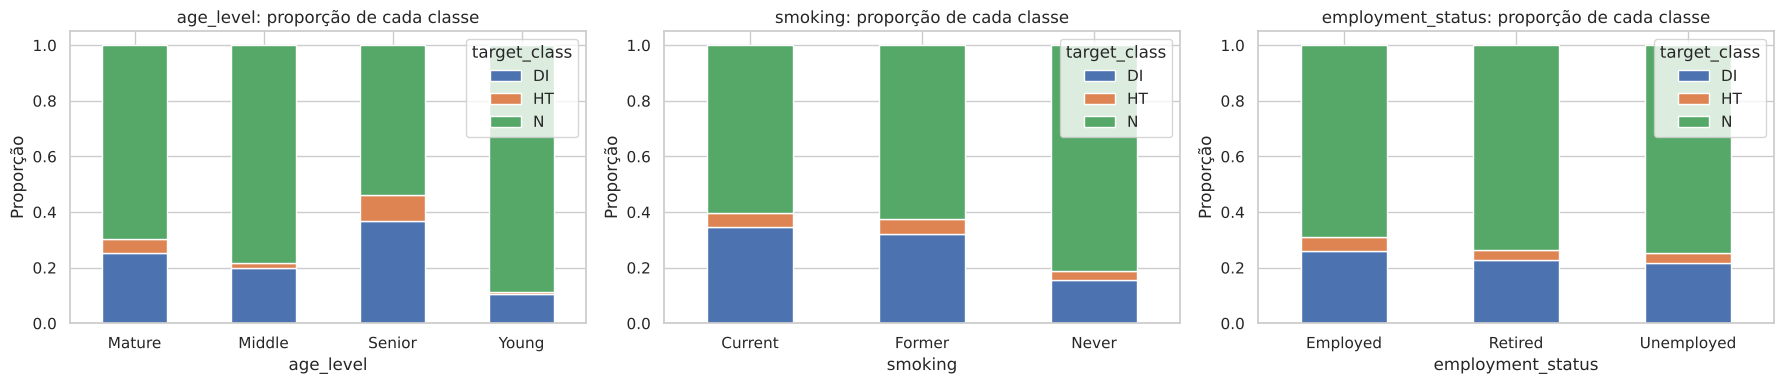

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, c in zip(axes, ['age_level', 'smoking', 'employment_status']):
    pd.crosstab(df[c], df['target_class'], normalize='index').plot(kind='bar', stacked=True, ax=ax)
    ax.set_title(f'{c}: proporção de cada classe'); ax.set_ylabel('Proporção'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Conclusões:**
- Todas as associações são **fracas** (V < 0.2).
- A mais forte é `age_level`, o que é coerente com a `age` ser um dos melhores preditores no notebook principal.
- A segunda é **`smoking`**, que a EDA do notebook principal não menciona.
- **`employment_status` não tem associação significativa** com `target_class` (p > 0.05): é a feature categórica **não informativa** mais clara.

### 1.2 Categóricas vs `target_regression`

Para uma variável categórica e um alvo numérico usamos a **ANOVA**: testa se a média de `target_regression` é igual em todas
as categorias. Como medida de força usamos o **η²** (eta ao quadrado): a fração da variância do alvo explicada pela variável.

In [5]:
rows = []
total_mean = df['target_regression'].mean()
ss_total = ((df['target_regression'] - total_mean) ** 2).sum()
for c in CAT_COLS + ['target_class']:
    groups = [g['target_regression'].values for _, g in df.groupby(c)]
    F, p = stats.f_oneway(*groups)
    ss_between = sum(len(g) * (g.mean() - total_mean) ** 2 for g in groups)
    rows.append({'Feature': c, 'F': round(F, 2), 'p-value': p, 'eta²': round(ss_between / ss_total, 4)})
pd.DataFrame(rows).sort_values('eta²', ascending=False).reset_index(drop=True)

,Feature,F,p-value,eta²
0,target_class,17.77,2.249780e-08,0.0175
1,age_level,2.09,1.000050e-01,0.0031
2,sugar_consumption,1.33,2.645062e-01,0.0013
3,bmi_level,0.80,4.924448e-01,0.0012
4,stress_level,0.91,4.027003e-01,0.0009
5,family_history,1.67,1.966096e-01,0.0008
6,physical_activity,0.31,7.351422e-01,0.0003
7,education_level,0.23,7.963327e-01,0.0002
8,low_hdl_cholesterol,0.41,5.223839e-01,0.0002
9,smoking,0.10,9.033311e-01,0.0001


**Conclusões:**
- **Nenhuma** feature categórica tem associação significativa com `target_regression` (todos os p > 0.05).
- Só o **outro alvo**, `target_class`, é significativo, mas explica menos de 2% da variância (η² ≈ 0.018).
- Confirma a conclusão do notebook principal: nenhuma feature disponível explica `target_regression`.

---
## 2. Efeito dos métodos de reamostragem na variância

O notebook principal compara o **desvio-padrão entre folds** de cada método. Esse valor depende do tamanho de cada fold de teste
(com k=10 os folds são mais pequenos, logo cada um é mais ruidoso), mas não diz quão fiável é o **resultado final** que reportamos.

A pergunta que interessa é: **se repetíssemos o método com outra divisão aleatória dos dados, quanto mudaria o resultado?**
(slides T4: *"the evaluation estimate itself has variance"*).

Para responder, repetimos cada método **20 vezes**, com sementes aleatórias diferentes, e medimos o desvio-padrão dos 20 resultados finais (F1 macro).

O **LOOCV** fica de fora: só há uma forma de deixar um paciente de fora de cada vez, por isso repeti-lo dá sempre o mesmo resultado.

*(Esta célula demora 1 a 3 minutos.)*

In [6]:
N_REPEATS = 20     # how many times each method is repeated
B = 50             # bootstrap samples per repetition

models = {'Logistic Regression': lambda: LogisticRegression(max_iter=1000),
          'LDA': lambda: LinearDiscriminantAnalysis()}

def new_pipe(make_model):
    return make_pipeline(StandardScaler(), make_model())

def holdout(make_model, seed):
    X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_class, test_size=0.2, stratify=y_class, random_state=seed)
    y_pred = new_pipe(make_model).fit(X_tr, y_tr).predict(X_te)
    return f1_score(y_te, y_pred, average='macro')

def cross_validation(make_model, k, seed):
    folds = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
    return cross_val_score(new_pipe(make_model), X_all, y_class, cv=folds, scoring='f1_macro').mean()

def bootstrap(make_model, seed):
    rng, n, scores = np.random.RandomState(seed), len(y_class), []
    for _ in range(B):
        train_idx = rng.randint(0, n, n)                       # sample with replacement
        oob_idx = np.setdiff1d(np.arange(n), train_idx)        # patients never drawn (out-of-bag)
        y_pred = new_pipe(make_model).fit(X_all[train_idx], y_class[train_idx]).predict(X_all[oob_idx])
        scores.append(f1_score(y_class[oob_idx], y_pred, average='macro'))
    return np.mean(scores)

results = []
for model_name, make_model in models.items():
    for method in ['Holdout 80/20', 'CV k=5', 'CV k=10', f'Bootstrap (B={B})']:
        for seed in range(N_REPEATS):
            if method.startswith('Holdout'):
                f1 = holdout(make_model, seed)
            elif method == 'CV k=5':
                f1 = cross_validation(make_model, 5, seed)
            elif method == 'CV k=10':
                f1 = cross_validation(make_model, 10, seed)
            else:
                f1 = bootstrap(make_model, seed)
            results.append({'Modelo': model_name, 'Método': method, 'Repetição': seed, 'F1 macro': f1})

results = pd.DataFrame(results)
summary = (results.groupby(['Modelo', 'Método'], sort=False)['F1 macro']
           .agg(Média='mean', Desvio_padrão='std', Mínimo='min', Máximo='max').round(4))
summary

Média  Desvio_padrão  Mínimo  Máximo
Modelo              Método                                                 
Logistic Regression Holdout 80/20     0.6209         0.0195  0.5957  0.6568
                    CV k=5            0.6145         0.0058  0.6065  0.6251
                    CV k=10           0.6123         0.0051  0.6068  0.6255
                    Bootstrap (B=50)  0.6209         0.0031  0.6154  0.6261
LDA                 Holdout 80/20     0.6214         0.0294  0.5850  0.6951
                    CV k=5            0.6212         0.0109  0.6012  0.6464
                    CV k=10           0.6220         0.0098  0.6025  0.6419
                    Bootstrap (B=50)  0.6223         0.0047  0.6127  0.6307

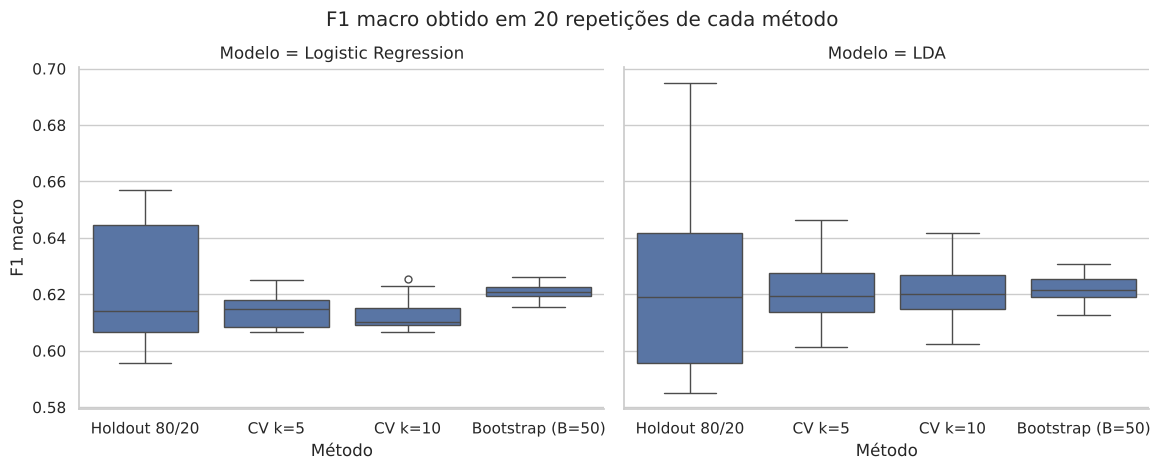

In [7]:
g = sns.catplot(data=results, x='Método', y='F1 macro', col='Modelo', kind='box', height=4.5, aspect=1.3)
g.fig.suptitle(f'F1 macro obtido em {N_REPEATS} repetições de cada método', y=1.04)
plt.show()

**Conclusões:**
- **O Holdout é o método com mais variância.** O resultado depende muito da divisão escolhida: o desvio-padrão é cerca de 3 vezes o do CV k=5.
  Com só 17 doentes HT no conjunto de teste, acertar ou falhar 1 ou 2 muda bastante o F1 macro.
- **CV k=5 e k=10 têm variância baixa e semelhante.** O k=10 não tem mais variância do que o k=5. O que aumenta com k é a diferença
  *entre folds* (folds mais pequenos), não a incerteza do resultado final, que é uma média de mais folds.
- **O Bootstrap é o mais estável,** porque cada resultado já é a média de 50 amostras. Em contrapartida, cada modelo treina só com
  ≈63% de pacientes distintos, o que pode tornar a estimativa pessimista.
- **As médias dos quatro métodos são praticamente iguais** (≈0.61–0.62). Os métodos diferem sobretudo na **variância** e no custo computacional, não no valor médio.
- O LDA tem mais variância do que a Regressão Logística em todos os métodos.

---
## 3. Resumo

| Ponto do enunciado | Resultado |
|---|---|
| Bivariada: categóricas vs `target_class` | Associações fracas (V < 0.2); `age_level` e `smoking` as mais fortes; `employment_status` não informativa |
| Bivariada: categóricas vs `target_regression` | Nenhuma associação significativa |
| Variância dos métodos de reamostragem | Holdout ≫ CV k=5 ≈ CV k=10 > Bootstrap; médias iguais |

## Referências

- James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer. Cap. 5 (Resampling Methods).
- Slides da unidade curricular APRAU 2026/27: T4 Evaluation & Resampling.
- Cramér, H. (1946). *Mathematical Methods of Statistics*. Princeton University Press.
- Documentação scikit-learn (https://scikit-learn.org) e SciPy (https://docs.scipy.org).